
# Seaborn — Hands-On Tutorial

This notebook follows the **Seaborn YouTube slide deck** step-by-step.

### Topics covered
- Seaborn setup and themes
- Built-in datasets
- Countplot
- Barplot
- Scatterplot and `hue`
- Lineplot
- Histogram
- KDE
- Boxplot
- Pairplot
- Heatmap
- Facets / `relplot`
- Styling
- Seaborn + Pandas
- Mini EDA challenge

**Run each section in order and experiment with the code.**


In [ ]:

# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

print("Seaborn version:", sns.__version__)


Seaborn version: 0.13.2


## 1. Explore Seaborn's built-in datasets

In [ ]:

# Load the tips dataset
tips = sns.load_dataset("tips")

tips.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:

# Basic information
tips.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [ ]:

# Quick statistical summary
tips.describe()


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 2. Countplot — How many observations are in each category?

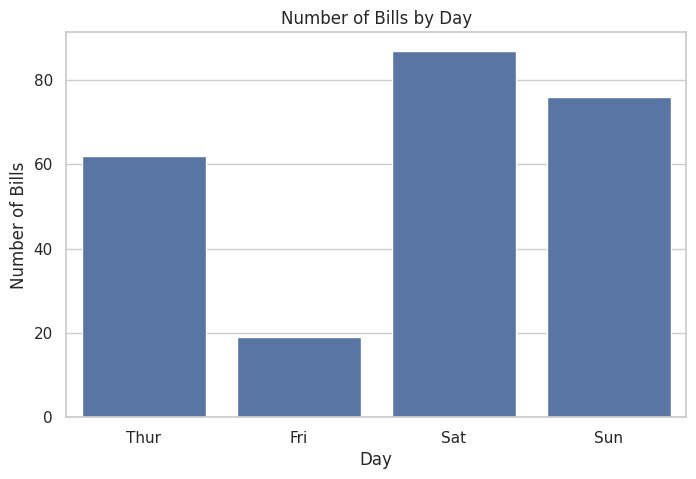

In [ ]:

plt.figure(figsize=(8, 5))

sns.countplot(data=tips, x="day")

plt.title("Number of Bills by Day")
plt.xlabel("Day")
plt.ylabel("Number of Bills")
plt.show()


## 3. Barplot — Compare a numerical value across categories

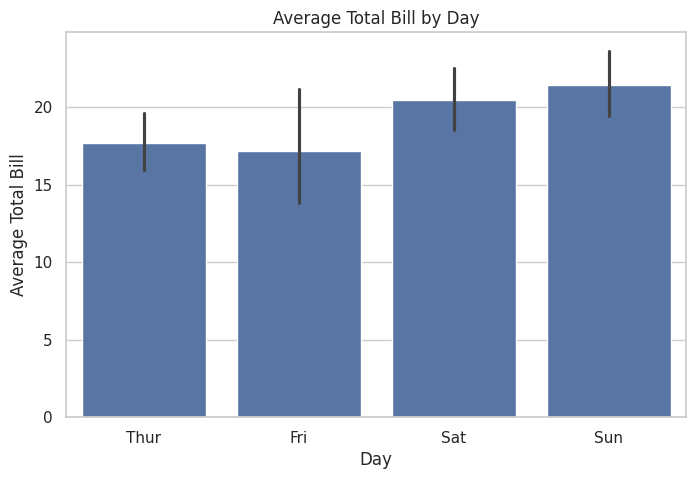

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(data=tips, x="day", y="total_bill")

plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")
plt.show()


## 4. Scatterplot — Explore relationships

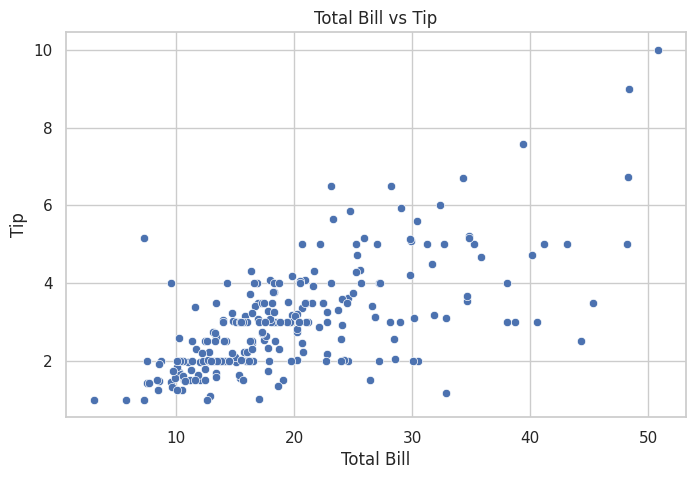

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip"
)

plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()


### Add another variable with `hue`

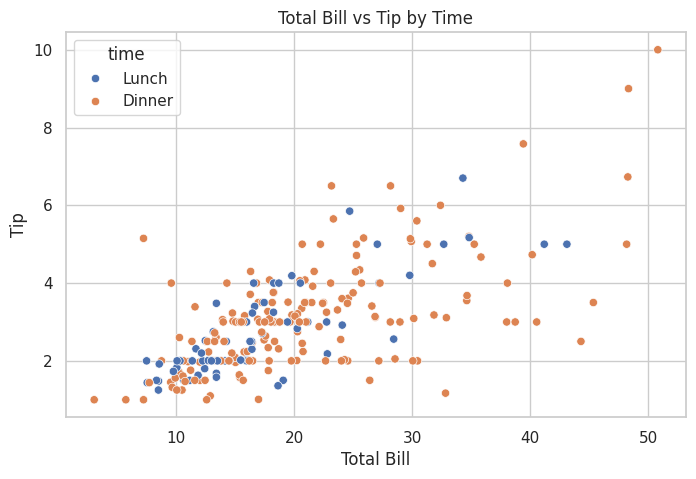

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time"
)

plt.title("Total Bill vs Tip by Time")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()


## 5. Lineplot — Visualize trends over time

In [ ]:

# Load the flights dataset
flights = sns.load_dataset("flights")

flights.head()


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


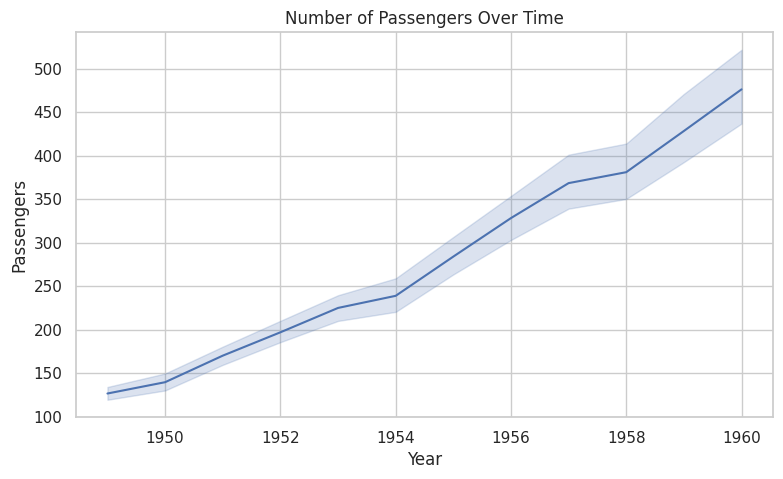

In [ ]:

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=flights,
    x="year",
    y="passengers"
)

plt.title("Number of Passengers Over Time")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()


## 6. Histogram — Understand a distribution

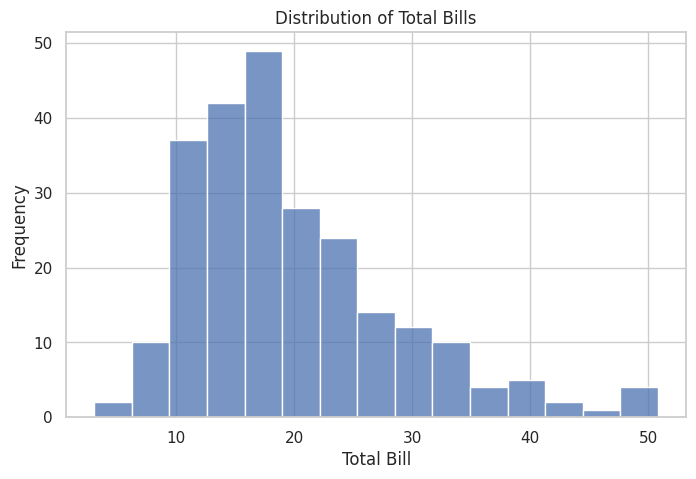

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=tips,
    x="total_bill",
    bins=15
)

plt.title("Distribution of Total Bills")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.show()


## 7. KDE — See the smooth shape of a distribution

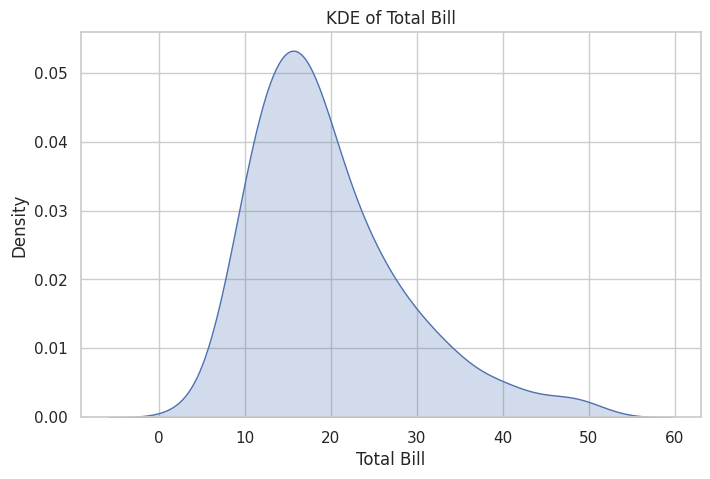

In [ ]:

plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=tips,
    x="total_bill",
    fill=True
)

plt.title("KDE of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Density")
plt.show()


## 8. Boxplot — Compare spread and identify potential outliers

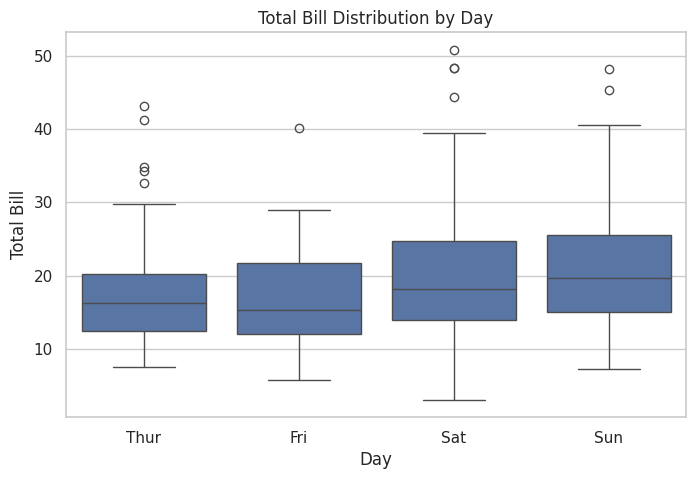

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=tips,
    x="day",
    y="total_bill"
)

plt.title("Total Bill Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Total Bill")
plt.show()


## 9. Pairplot — Explore several relationships at once

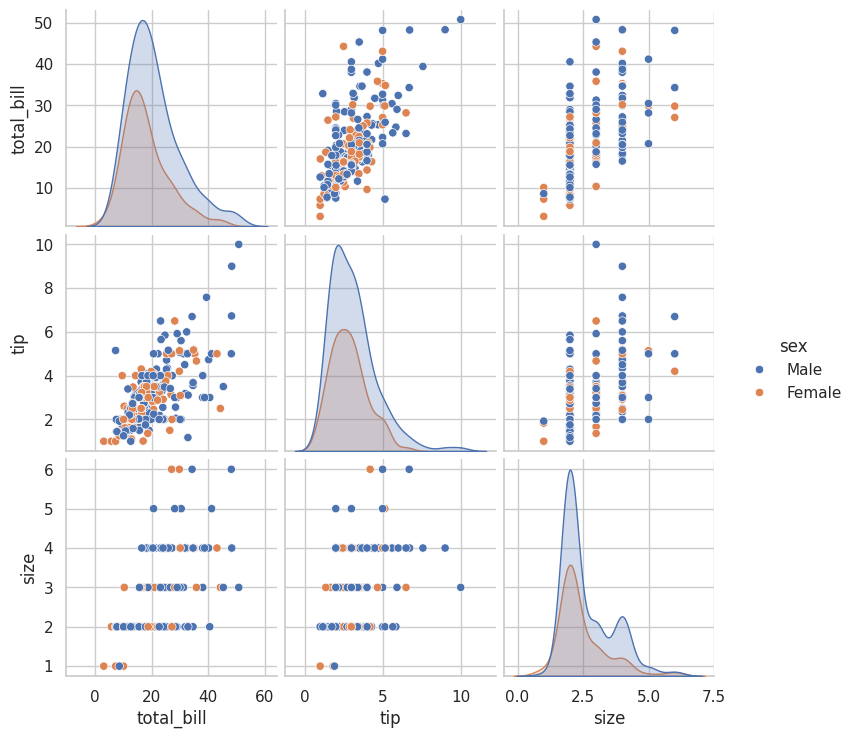

In [ ]:

sns.pairplot(
    tips,
    hue="sex"
)

plt.show()


## 10. Heatmap — Visualize correlations

In [ ]:

# Select numerical columns and calculate correlation
corr = tips.select_dtypes("number").corr()

corr


,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


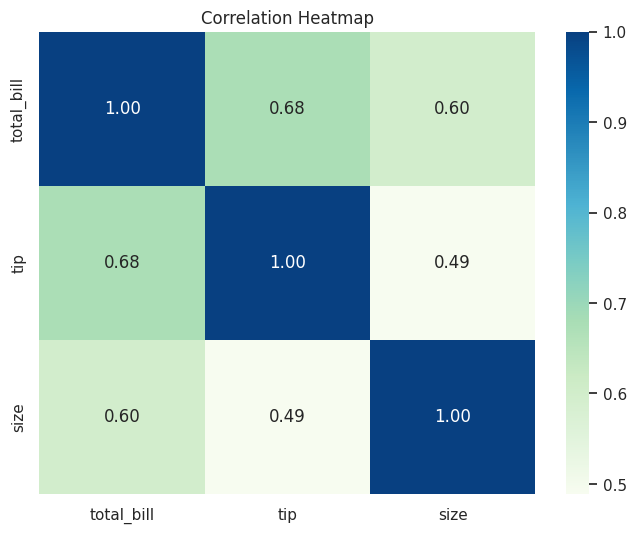

In [ ]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="GnBu"
)

plt.title("Correlation Heatmap")
plt.show()


## 11. Facets with `relplot` — Split one visualization into panels

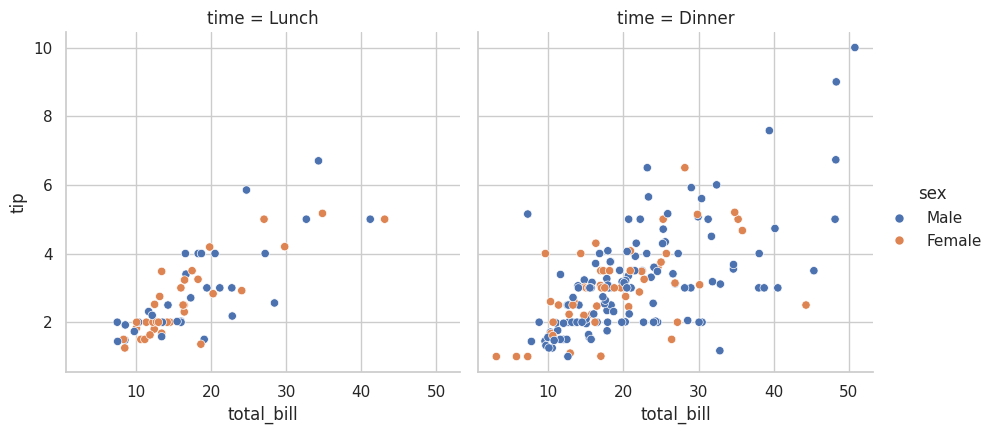

In [ ]:

sns.relplot(
    data=tips,
    x="total_bill",
    y="tip",
    col="time",
    hue="sex",
    height=4.5,
    aspect=1
)

plt.show()


## 12. Styling Seaborn plots

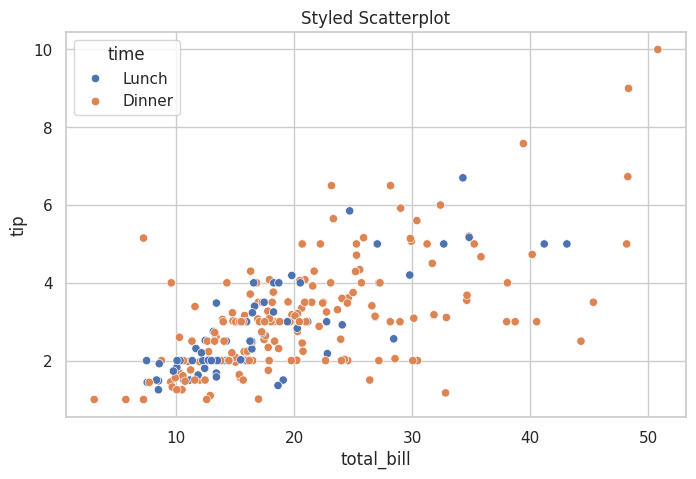

In [ ]:

# Try different themes:
# "darkgrid", "whitegrid", "dark", "white", "ticks"

sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time"
)

plt.title("Styled Scatterplot")
plt.show()


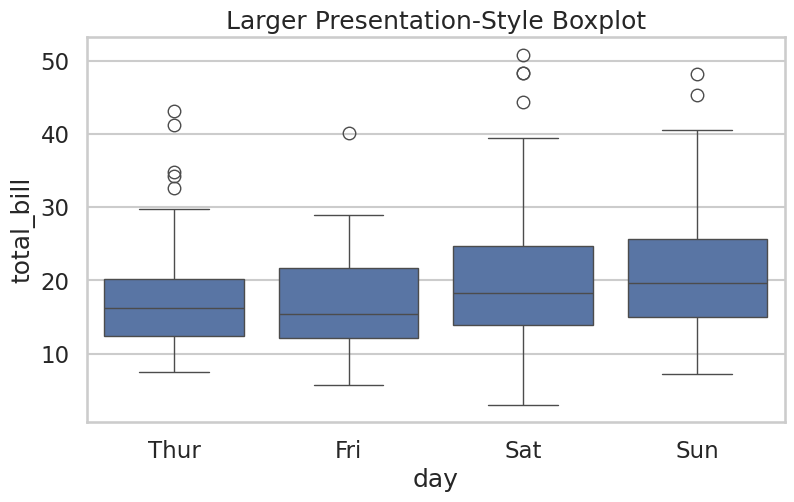

In [ ]:

# Try a different context
sns.set_context("talk")

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tips,
    x="day",
    y="total_bill"
)

plt.title("Larger Presentation-Style Boxplot")
plt.show()

# Reset
sns.set_context("notebook")


## 13. Seaborn + Pandas — Real-world workflow

In [ ]:

# Create a small DataFrame similar to a real CSV file
sales = pd.DataFrame({
    "region": ["North", "South", "East", "West", "North", "South", "East", "West"],
    "sales": [42000, 38000, 51000, 46000, 47000, 41000, 54000, 49000]
})

sales


,region,sales
0,North,42000
1,South,38000
2,East,51000
3,West,46000
4,North,47000
5,South,41000
6,East,54000
7,West,49000


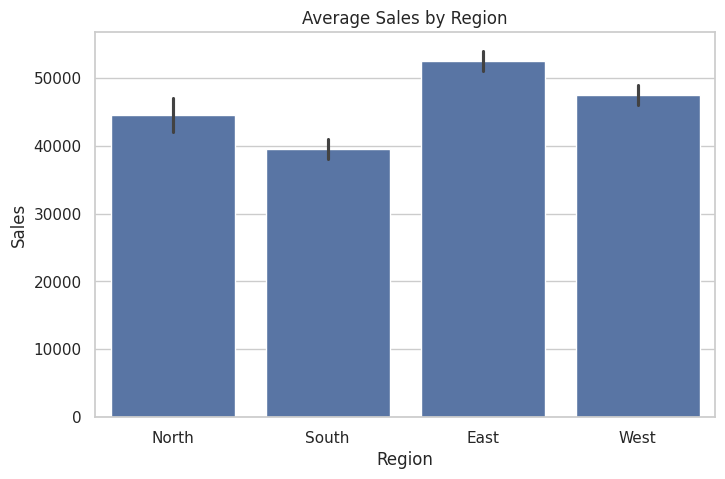

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=sales,
    x="region",
    y="sales"
)

plt.title("Average Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.show()



### Using your own CSV

If you have a CSV file, the workflow is:

```python
df = pd.read_csv("your_file.csv")

sns.barplot(
    data=df,
    x="category",
    y="value"
)

plt.show()
```


## 14. Mini EDA Challenge


Use the `tips` dataset and answer these questions **with visualizations**:

1. Which day has the most observations?
2. Does a larger bill tend to mean a larger tip?
3. How is the total bill distributed?
4. Which day has the widest spread in total bills?
5. Is there a visible relationship between the numerical variables?
6. Does the relationship between bill and tip appear different for lunch and dinner?


In [ ]:

# Challenge 1
# Which day has the most observations?

# Your code here


In [ ]:

# Challenge 2
# Does a larger bill tend to mean a larger tip?

# Your code here


In [ ]:

# Challenge 3
# How is the total bill distributed?

# Your code here


In [ ]:

# Challenge 4
# Which day has the widest spread?

# Your code here


In [ ]:

# Challenge 5
# Explore relationships among numerical variables.

# Your code here


In [ ]:

# Challenge 6
# Compare the bill-tip relationship for lunch and dinner.

# Your code here



## Quick Cheat Sheet

| Question | Seaborn plot |
|---|---|
| How many observations? | `countplot()` |
| Compare categories | `barplot()` |
| Relationship between two variables | `scatterplot()` |
| Trend over time | `lineplot()` |
| Distribution | `histplot()` |
| Smooth distribution | `kdeplot()` |
| Compare spread / outliers | `boxplot()` |
| Explore many relationships | `pairplot()` |
| Correlations | `heatmap()` |
| Split a visualization into panels | `relplot()` |



# Key takeaway

A good visualization starts with a **question**, not a chart.

**Pandas → clean and prepare the data**

**Seaborn → visualize patterns**

**Your interpretation → turn patterns into insights**
